In [4]:
import plotly.express as px
import plotly.graph_objects as go
import pandas as pd
import numpy as np
from data_preparation import read_all_granularity_data
#
metadata_all, series_all, metadata_region_all, region_series_all, metadata_country_all, country_series_all = read_all_granularity_data()

In [127]:
# from data_preparation import get_metadata, get_series,clip_missing_prone_values, read_region_and_country_series
#
# series_with_heavy_missing, metadata_with_heavy_missing = get_series(), get_metadata()
# division_missing_counts, metadata, series = clip_missing_prone_values(metadata_with_heavy_missing, series_with_heavy_missing)
# region_series, metadata_region, country_series, metadata_country = read_region_and_country_series()

In [128]:
metadata_region_all

,Country,Population,Latitude,Longitude,Count
Region,,,,,
Barisal,Bangladesh,355739,22.657433,90.329767,3
Bihar,India,6928787,25.708822,85.630522,41
Chhattisgarh,India,2872929,21.400350,82.035208,12
Chittagong,Bangladesh,4863428,22.830245,91.403291,11
Dhaka,Bangladesh,12421465,23.735636,90.334793,14
Haryana,India,6280342,29.229848,76.427341,27
Jharkhand,India,3061175,23.793406,85.894763,16
Khulna,Bangladesh,1906080,23.149120,89.292880,5
Madhya Pradesh,India,11620902,23.683922,77.800602,50


In [129]:
metadata_all

,Zone,Country,Region,Population,Latitude,Longitude
index,,,,,,
Adilabad_Telangana,Adilabad,India,Telangana,118526,19.6720,78.5359
Agra_Uttar Pradesh,Agra,India,Uttar Pradesh,1430055,27.1833,78.0167
Ajodhya_Uttar Pradesh,Ajodhya,India,Uttar Pradesh,53293,26.7991,82.2047
Aligarh_Uttar Pradesh,Aligarh,India,Uttar Pradesh,753207,27.8815,78.0746
Allahabad_Uttar Pradesh,Allahabad,India,Uttar Pradesh,1073438,25.4448,81.8432
...,...,...,...,...,...,...
Vidisha_Madhya Pradesh,Vidisha,India,Madhya Pradesh,140045,23.5260,77.8109
Vrindavan_Uttar Pradesh,Vrindavan,India,Uttar Pradesh,60195,27.5811,77.6966
Wanparti_Telangana,Wanparti,India,Telangana,55182,16.3674,78.0689


In [130]:
country_series_all.head(5)

,Bangladesh,India
time,,
2017-01-01 00:00:00,208.49,134.76
2017-01-01 01:00:00,203.43,123.35
2017-01-01 02:00:00,182.11,116.38
2017-01-01 03:00:00,172.29,118.00
2017-01-01 04:00:00,164.74,121.97


In [131]:
# division_missing_percentage = division_missing_counts / series.shape[0] * 100
# division_missing_percentage.name = "Missing %"

In [132]:
from data_preparation import country_color_dict

# from exploration import country_color_dict
#
metadata_all['color'] = metadata_all.apply(lambda x: country_color_dict[x.Country],axis=1)
metadata_region_all['color'] = metadata_region_all.apply(lambda x: country_color_dict[x.Country],axis=1)

In [133]:
# fig = px.bar(division_missing_percentage)
# # fig = px.bar(division_missing_percentage.diff())
# fig.show()

In [134]:
fig = px.bar(metadata_region_all.Count, color=metadata_region_all.Country)
fig.show()

In [135]:
metadata_region_sorted = metadata_region_all.sort_values('Country')
metadata_region_sorted = metadata_region_all[metadata_region_all.Country!="Bangladesh"]

In [136]:
fig = go.Figure(data=[go.Bar(
    x=metadata_region_sorted.index,
    y=metadata_region_sorted.Count,
    marker_color=metadata_region_sorted.color # marker color can be a single color value or an iterable
)])
fig.update_layout(title_text='',yaxis_title='Number of Zones',xaxis_title='Regions')

In [137]:
fig = px.bar(metadata_all.Country.value_counts())
fig.show()

In [138]:
metadata_region_all

,Country,Population,Latitude,Longitude,Count,color
Region,,,,,,
Barisal,Bangladesh,355739,22.657433,90.329767,3,#228B22
Bihar,India,6928787,25.708822,85.630522,41,#F4C430
Chhattisgarh,India,2872929,21.400350,82.035208,12,#F4C430
Chittagong,Bangladesh,4863428,22.830245,91.403291,11,#228B22
Dhaka,Bangladesh,12421465,23.735636,90.334793,14,#228B22
Haryana,India,6280342,29.229848,76.427341,27,#F4C430
Jharkhand,India,3061175,23.793406,85.894763,16,#F4C430
Khulna,Bangladesh,1906080,23.149120,89.292880,5,#228B22
Madhya Pradesh,India,11620902,23.683922,77.800602,50,#F4C430


# Required All Points in a Map

In [139]:
metadata_region_all

,Country,Population,Latitude,Longitude,Count,color
Region,,,,,,
Barisal,Bangladesh,355739,22.657433,90.329767,3,#228B22
Bihar,India,6928787,25.708822,85.630522,41,#F4C430
Chhattisgarh,India,2872929,21.400350,82.035208,12,#F4C430
Chittagong,Bangladesh,4863428,22.830245,91.403291,11,#228B22
Dhaka,Bangladesh,12421465,23.735636,90.334793,14,#228B22
Haryana,India,6280342,29.229848,76.427341,27,#F4C430
Jharkhand,India,3061175,23.793406,85.894763,16,#F4C430
Khulna,Bangladesh,1906080,23.149120,89.292880,5,#228B22
Madhya Pradesh,India,11620902,23.683922,77.800602,50,#F4C430


In [140]:
fig = go.Figure(data=go.Scattergeo(
    lon=metadata_region_all['Longitude'],
    lat=metadata_region_all['Latitude'],
    text=metadata_region_all.index,
    mode='markers',
    # marker_color=metadata_division['Population'],
))

fig.update_layout(
    title='Most trafficked US airports<br>(Hover for airport names)',
    geo_scope='asia',
)
# fig.update_layout(mapbox_style="carto-positron",
#                   mapbox_zoom=3, mapbox_center={"lat": 37.0902, "lon": -95.7129})
fig.show()

In [6]:
metadata_bd = metadata_all[metadata_all.Country=="Bangladesh"].copy()
# metadata_bd.color = country_color_dict.get("Bangladesh")
metadata_bd["color"] = country_color_dict.get("Bangladesh")
metadata_bd

,Zone,Country,Region,Population,Latitude,Longitude,color
index,,,,,,,
Azimpur_Dhaka,Azimpur,Bangladesh,Dhaka,96641,23.7298,90.3854,#96AED0
Barisal_Barisal,Barisal,Bangladesh,Barisal,202242,22.7050,90.3701,#96AED0
Bhairab Bazar_Dhaka,Bhairab Bazar,Bangladesh,Dhaka,105457,24.0524,90.9764,#96AED0
Bhola_Barisal,Bhola,Bangladesh,Barisal,99079,22.6876,90.6440,#96AED0
Bogra_Rajshahi,Bogra,Bangladesh,Rajshahi,210000,24.8510,89.3711,#96AED0
Chittagong_Chittagong,Chittagong,Bangladesh,Chittagong,3920222,22.3384,91.8317,#96AED0
Comilla_Chittagong,Comilla,Bangladesh,Chittagong,389411,23.4619,91.1850,#96AED0
Dhaka_Dhaka,Dhaka,Bangladesh,Dhaka,10356500,23.7104,90.4074,#96AED0
Dinajpur_Rangpur,Dinajpur,Bangladesh,Rangpur,206234,25.6274,88.6378,#96AED0


In [171]:
def plotly_marker_scatter_mapbox(geo_points,lat,lon,zoom):
    # mapbox_access_token = open(".mapbox_token").read()
    from paths import MAPBOX_TOKEN  # kept in the git-ignored .env file
    mapbox_access_token = MAPBOX_TOKEN

    fig = go.Figure()

    fig.add_trace(go.Scattermapbox(
        lat=geo_points.Latitude,
        lon=geo_points.Longitude,
        mode='markers',
        marker=go.scattermapbox.Marker(
            size=15, color= 'black'
        )
    ))

    fig.add_trace(go.Scattermapbox(
        lat=geo_points.Latitude,
        lon=geo_points.Longitude,
        mode='markers',
        marker=go.scattermapbox.Marker(
            size=12, color=geo_points.color
        ),
        text=geo_points.index,
    ))

    fig.update_layout(
        height=600*1.35,
        width=900*1.35,
        hovermode='closest',
        mapbox=dict(
            accesstoken=mapbox_access_token,
            bearing=0,
            center=go.layout.mapbox.Center(
                lat=lat,
                lon=lon
            ),
            pitch=0,
            zoom=zoom
        )
    )
    fig.update_layout(mapbox_style="streets")

    fig.show()



country_color_dict = {'India': '#D096AE', 'Myanmar': '#990000', 'Bangladesh': '#96AED0'}
metadata_region_all['color'] = metadata_region_all.apply(lambda x: country_color_dict[x.Country],axis=1)
lat,lon,zoom = 23.81,82.1,5
plotly_marker_scatter_mapbox(metadata_region_all,lat,lon,zoom)

In [172]:
import plotly.graph_objects as go
import pandas as pd
import numpy as np


def plotly_marker_scatter_mapbox(geo_points, lat, lon, zoom):
    """
    Enhanced map visualization with legend, focused view on Bangladesh,
    and improved visual elements.
    """
    from paths import MAPBOX_TOKEN  # kept in the git-ignored .env file
    mapbox_access_token = MAPBOX_TOKEN

    fig = go.Figure()

    # Add markers with black outline for each country
    for country, color in country_color_dict.items():
        country_data = geo_points[geo_points['Country'] == country]

        if len(country_data) > 0:
            # Black outline
            fig.add_trace(go.Scattermapbox(
                lat=country_data.Latitude,
                lon=country_data.Longitude,
                mode='markers',
                marker=go.scattermapbox.Marker(
                    size=15,
                    color='black'
                ),
                showlegend=False,
                hoverinfo='skip'
            ))

            # Colored markers with legend
            fig.add_trace(go.Scattermapbox(
                lat=country_data.Latitude,
                lon=country_data.Longitude,
                mode='markers',
                marker=go.scattermapbox.Marker(
                    size=12,
                    color=color
                ),
                text=country_data.index,
                name=country,
                hovertemplate='<b>%{text}</b><br>' +
                              'Lat: %{lat:.4f}<br>' +
                              'Lon: %{lon:.4f}<br>' +
                              '<extra></extra>'
            ))

    # Adjusted center and zoom to focus more on Bangladesh
    # This reduces the visible area of India and Myanmar
    fig.update_layout(
        # height=810,  # 600*1.35
        # width=1215,  # 900*1.35
        height=800,
        width=1000,
        hovermode='closest',
        mapbox=dict(
            accesstoken=mapbox_access_token,
            bearing=0,
            center=go.layout.mapbox.Center(
                lat=lat,
                lon=lon
            ),
            pitch=0,
            zoom=zoom,
            style="streets"
        ),
        # Enhanced legend
        legend=dict(
            title=dict(
                text='<b>Country Locations</b>',
                font=dict(size=14, family='Arial, sans-serif')
            ),
            x=0.83,
            y=0.98,
            bgcolor='rgba(255, 255, 255, 0.9)',
            bordercolor='black',
            borderwidth=1,
            font=dict(size=12, family='Arial, sans-serif'),
            itemsizing='constant'
        ),
        # Add margin for better layout
        margin=dict(l=0, r=0, t=40, b=0),
        # Title
        title=dict(
            text='Geographic Distribution of Sampling Sites',
            x=0.5,
            xanchor='center',
            font=dict(size=16, family='Arial, sans-serif')
        )
    )

    # Add scale bar annotation (approximate)
    fig.add_annotation(
        x=0.95,
        y=0.05,
        xref='paper',
        yref='paper',
        text='<b>Scale</b><br>50 km ━━━',
        showarrow=False,
        bgcolor='rgba(255, 255, 255, 0.9)',
        bordercolor='black',
        borderwidth=1,
        borderpad=5,
        font=dict(size=10, family='Arial, sans-serif'),
        align='left'
    )

    # Add north arrow annotation
    fig.add_annotation(
        x=0.95,
        y=0.15,
        xref='paper',
        yref='paper',
        text='<b>N</b><br>↑',
        showarrow=False,
        bgcolor='rgba(255, 255, 255, 0.9)',
        bordercolor='black',
        borderwidth=1,
        borderpad=5,
        font=dict(size=14, family='Arial, sans-serif', color='black')
    )

    return fig


# Example usage with your data structure
# Country color scheme
country_color_dict = {
    'India': '#D096AE',  # Pink
    'Myanmar': '#990000',  # Dark red
    'Bangladesh': '#96AED0'  # Blue
}

# Apply colors to your dataframe
metadata_region_all['color'] = metadata_region_all.apply(
    lambda x: country_color_dict[x.Country],
    axis=1
)

# Adjusted coordinates to focus more on Bangladesh
# You may need to fine-tune these values based on your data distribution
lat, lon, zoom = 23.81, 90.0, 5.25  # Shifted longitude east, increased zoom

# Create the map
fig = plotly_marker_scatter_mapbox(metadata_region_all, lat, lon, zoom)
fig.show()

In [144]:
import numpy as np

def mapbox_scale_length_km(latitude, zoom, map_width_px, desired_km=50):
    """
    Calculate the approximate pixel width of a scale bar for Mapbox/WebMercator.
    """
    meters_per_pixel = 156543.03392 * np.cos(np.deg2rad(latitude)) / (2 ** zoom)
    desired_meters = desired_km * 1000
    pixels = desired_meters / meters_per_pixel
    return pixels

# Example:
latitude = 23.81  # center latitude
zoom = 5.25
map_width_px = 1000

scale_px = mapbox_scale_length_km(latitude, zoom, map_width_px)
print(f"At zoom={zoom}, latitude={latitude}, a 50 km scale bar ≈ {scale_px:.1f} pixels wide.")


At zoom=5.25, latitude=23.81, a 50 km scale bar ≈ 13.3 pixels wide.


In [173]:
import plotly.graph_objects as go
import pandas as pd
import numpy as np


def plotly_marker_scatter_mapbox(geo_points, lat, lon, zoom):
    """
    Enhanced map visualization with legend, focused view on Bangladesh,
    and improved visual elements.
    """
    from paths import MAPBOX_TOKEN  # kept in the git-ignored .env file
    mapbox_access_token = MAPBOX_TOKEN

    fig = go.Figure()

    # Add markers with black outline for each country
    for country, color in country_color_dict.items():
        country_data = geo_points[geo_points['Country'] == country]

        if len(country_data) > 0:
            # Black outline
            fig.add_trace(go.Scattermapbox(
                lat=country_data.Latitude,
                lon=country_data.Longitude,
                mode='markers',
                marker=go.scattermapbox.Marker(
                    size=15,
                    color='black'
                ),
                showlegend=False,
                hoverinfo='skip'
            ))

            # Colored markers with legend
            fig.add_trace(go.Scattermapbox(
                lat=country_data.Latitude,
                lon=country_data.Longitude,
                mode='markers',
                marker=go.scattermapbox.Marker(
                    size=12,
                    color=color
                ),
                text=country_data.index,
                name=country,
                hovertemplate='<b>%{text}</b><br>' +
                              'Lat: %{lat:.4f}<br>' +
                              'Lon: %{lon:.4f}<br>' +
                              '<extra></extra>'
            ))

    # Adjusted center and zoom to focus more on Bangladesh
    # This reduces the visible area of India and Myanmar
    fig.update_layout(
        # height=810,  # 600*1.35
        # width=1215,  # 900*1.35
        height=800,
        width=1000,
        hovermode='closest',
        mapbox=dict(
            accesstoken=mapbox_access_token,
            bearing=0,
            center=go.layout.mapbox.Center(
                lat=lat,
                lon=lon
            ),
            pitch=0,
            zoom=zoom,
            style="streets"
        ),
        # Enhanced legend
        legend=dict(
            title=dict(
                text='<b>Country Locations</b>',
                font=dict(size=14, family='Arial, sans-serif')
            ),
            x=0.83,
            y=0.98,
            bgcolor='rgba(255, 255, 255, 0.9)',
            bordercolor='black',
            borderwidth=1,
            font=dict(size=12, family='Arial, sans-serif'),
            itemsizing='constant'
        ),
        # Add margin for better layout
        margin=dict(l=0, r=0, t=40, b=0),
        # Title
        title=dict(
            text='Geographic Distribution of Sampling Sites',
            x=0.5,
            xanchor='center',
            font=dict(size=16, family='Arial, sans-serif')
        )
    )

    # Add scale bar annotation (approximate)
    map_width_px = 800
    scale_px = mapbox_scale_length_km(latitude, zoom, map_width_px)
    print(scale_px)
    scale_fraction = scale_px / map_width_px

    fig.add_shape(
        type='line',
        xref='paper', yref='paper',
        x0=0.93 - scale_fraction, x1=0.93,  # 50 km bar length
        y0=0.05, y1=0.05,
        line=dict(color='black', width=3)
    )

    fig.add_annotation(
        x=0.93 - scale_fraction / 2,
        y=0.06,
        text='50 km',
        showarrow=False,
        xref='paper', yref='paper',
        font=dict(size=10, family='Arial')
    )

    # Add north arrow annotation
    fig.add_annotation(
        x=0.95,
        y=0.15,
        xref='paper',
        yref='paper',
        text='<b>N</b><br>↑',
        showarrow=False,
        bgcolor='rgba(255, 255, 255, 0.9)',
        bordercolor='black',
        borderwidth=1,
        borderpad=5,
        font=dict(size=14, family='Arial, sans-serif', color='black')
    )

    return fig


# Example usage with your data structure
# Country color scheme
country_color_dict = {
    'India': '#D096AE',  # Pink
    'Myanmar': '#990000',  # Dark red
    'Bangladesh': '#96AED0'  # Blue
}

# Apply colors to your dataframe
metadata_region_all['color'] = metadata_region_all.apply(
    lambda x: country_color_dict[x.Country],
    axis=1
)

# Adjusted coordinates to focus more on Bangladesh
# You may need to fine-tune these values based on your data distribution
lat, lon, zoom = 23.81, 90.0, 5.25  # Shifted longitude east, increased zoom

# Create the map
fig = plotly_marker_scatter_mapbox(metadata_region_all, lat, lon, zoom)
fig.show()

In [174]:
import plotly.graph_objects as go
import pandas as pd
import numpy as np

def add_dynamic_scalebar(fig, latitude, zoom, map_width_px=1000):
    """
    Adds a dynamic scale bar that adjusts between 50, 100, 200, 500 km
    based on zoom level and latitude.
    """
    # Web Mercator meters per pixel
    meters_per_pixel = 156543.03392 * np.cos(np.deg2rad(latitude)) / (2 ** zoom)

    # Approximate map width on the ground (in km)
    map_width_km = (meters_per_pixel * map_width_px) / 1000.0

    # Pick a round number (50, 100, 200, 500 km)
    if map_width_km < 100:
        desired_km = 10
    elif map_width_km < 400:
        desired_km = 50
    elif map_width_km < 800:
        desired_km = 100
    elif map_width_km < 1600:
        desired_km = 200
    else:
        desired_km = 500

    # Compute bar length in pixels and fraction of figure width
    bar_pixels = (desired_km * 1000) / meters_per_pixel
    bar_fraction = bar_pixels / map_width_px

    # Add line (scale bar)
    fig.add_shape(
        type='line',
        xref='paper', yref='paper',
        x0=0.90 - bar_fraction, x1=0.90,
        y0=0.05, y1=0.05,
        line=dict(color='black', width=4)
    )

    # Add label
    fig.add_annotation(
        x=0.90 - bar_fraction / 2,
        y=0.06,
        xref='paper', yref='paper',
        text=f"{desired_km} km",
        showarrow=False,
        font=dict(size=12, family='Arial', color='black')
    )

    return fig

def plotly_marker_scatter_mapbox(geo_points, lat, lon, zoom):
    """
    Enhanced map visualization with legend, focused view on Bangladesh,
    and improved visual elements.
    """
    from paths import MAPBOX_TOKEN  # kept in the git-ignored .env file
    mapbox_access_token = MAPBOX_TOKEN

    fig = go.Figure()

    # Add markers with black outline for each country
    for country, color in country_color_dict.items():
        country_data = geo_points[geo_points['Country'] == country]

        if len(country_data) > 0:
            # Black outline
            fig.add_trace(go.Scattermapbox(
                lat=country_data.Latitude,
                lon=country_data.Longitude,
                mode='markers',
                marker=go.scattermapbox.Marker(
                    size=15,
                    color='black'
                ),
                showlegend=False,
                hoverinfo='skip'
            ))

            # Colored markers with legend
            fig.add_trace(go.Scattermapbox(
                lat=country_data.Latitude,
                lon=country_data.Longitude,
                mode='markers',
                marker=go.scattermapbox.Marker(
                    size=12,
                    color=color
                ),
                text=country_data.index,
                name=country,
                hovertemplate='<b>%{text}</b><br>' +
                              'Lat: %{lat:.4f}<br>' +
                              'Lon: %{lon:.4f}<br>' +
                              '<extra></extra>'
            ))

    # Adjusted center and zoom to focus more on Bangladesh
    # This reduces the visible area of India and Myanmar
    fig.update_layout(
        # height=810,  # 600*1.35
        # width=1215,  # 900*1.35
        height=800,
        width=1000,
        hovermode='closest',
        mapbox=dict(
            accesstoken=mapbox_access_token,
            bearing=0,
            center=go.layout.mapbox.Center(
                lat=lat,
                lon=lon
            ),
            pitch=0,
            zoom=zoom,
            style="streets"
        ),
        # Enhanced legend
        legend=dict(
            title=dict(
                text='<b>Country Locations</b>',
                font=dict(size=14, family='Arial, sans-serif')
            ),
            x=0.83,
            y=0.98,
            bgcolor='rgba(255, 255, 255, 0.9)',
            bordercolor='black',
            borderwidth=1,
            font=dict(size=12, family='Arial, sans-serif'),
            itemsizing='constant'
        ),
        # Add margin for better layout
        margin=dict(l=0, r=0, t=40, b=0),
        # Title
        title=dict(
            text='Geographic Distribution of Sampling Sites',
            x=0.5,
            xanchor='center',
            font=dict(size=16, family='Arial, sans-serif')
        )
    )

    # Add north arrow annotation
    fig.add_annotation(
        x=0.95,
        y=0.15,
        xref='paper',
        yref='paper',
        text='<b>N</b><br>↑',
        showarrow=False,
        bgcolor='rgba(255, 255, 255, 0.9)',
        bordercolor='black',
        borderwidth=1,
        borderpad=5,
        font=dict(size=14, family='Arial, sans-serif', color='black')
    )

    fig = add_dynamic_scalebar(fig, lat, zoom, map_width_px=1000)

    return fig


# Example usage with your data structure
# Country color scheme
country_color_dict = {
    'India': '#D096AE',  # Pink
    'Myanmar': '#990000',  # Dark red
    'Bangladesh': '#96AED0'  # Blue
}

# Apply colors to your dataframe
metadata_region_all['color'] = metadata_region_all.apply(
    lambda x: country_color_dict[x.Country],
    axis=1
)

# Adjusted coordinates to focus more on Bangladesh
# You may need to fine-tune these values based on your data distribution
lat, lon, zoom = 23.81, 90.0, 6  # Shifted longitude east, increased zoom

# Create the map
fig = plotly_marker_scatter_mapbox(metadata_region_all, lat, lon, zoom)
fig.show()

In [175]:
def plotly_marker_scatter_mapbox(geo_points, lat, lon, zoom):
    """
    Enhanced map visualization with legend, focused view on Bangladesh,
    and improved visual elements.
    """
    from paths import MAPBOX_TOKEN  # kept in the git-ignored .env file
    mapbox_access_token = MAPBOX_TOKEN

    fig = go.Figure()

    # Add markers with black outline for each country
    for country, color in country_color_dict.items():
        country_data = geo_points[geo_points['Country'] == country]

        if len(country_data) > 0:
            # Black outline
            fig.add_trace(go.Scattermapbox(
                lat=country_data.Latitude,
                lon=country_data.Longitude,
                mode='markers',
                marker=go.scattermapbox.Marker(
                    size=15,
                    color='black'
                ),
                showlegend=False,
                hoverinfo='skip'
            ))

            # Colored markers with legend
            fig.add_trace(go.Scattermapbox(
                lat=country_data.Latitude,
                lon=country_data.Longitude,
                mode='markers',
                marker=go.scattermapbox.Marker(
                    size=12,
                    color=color
                ),
                text=country_data.index,
                name=country,
                hovertemplate='<b>%{text}</b><br>' +
                              'Lat: %{lat:.4f}<br>' +
                              'Lon: %{lon:.4f}<br>' +
                              '<extra></extra>'
            ))

    # Adjusted center and zoom to focus more on Bangladesh
    # This reduces the visible area of India and Myanmar
    fig.update_layout(
        height=810,  # 600*1.35
        width=1215,  # 900*1.35
        hovermode='closest',
        mapbox=dict(
            accesstoken=mapbox_access_token,
            bearing=0,
            center=go.layout.mapbox.Center(
                lat=lat,
                lon=lon
            ),
            pitch=0,
            zoom=zoom,
            style="streets"
        ),
        # Enhanced legend
        legend=dict(
            title=dict(
                text='<b>Sampling Locations</b>',
                font=dict(size=14, family='Arial, sans-serif')
            ),
            x=0.02,
            y=0.98,
            bgcolor='rgba(255, 255, 255, 0.9)',
            bordercolor='black',
            borderwidth=1,
            font=dict(size=12, family='Arial, sans-serif'),
            itemsizing='constant'
        ),
        # Add margin for better layout
        margin=dict(l=0, r=0, t=40, b=0),
        # Title
        title=dict(
            text='Geographic Distribution of Sampling Sites',
            x=0.5,
            xanchor='center',
            font=dict(size=16, family='Arial, sans-serif')
        )
    )

    # Calculate accurate scale bar
    # At zoom level, the map width in meters at the equator
    # Scale at equator = 156543.03392 * cos(latitude) / (2^zoom) meters per pixel
    # For a map width of ~1215 pixels
    import math

    # Calculate meters per pixel at the given latitude and zoom
    meters_per_pixel = 156543.03392 * math.cos(lat * math.pi / 180) / (2 ** zoom)

    # We want a nice round number for the scale bar (like 50, 100, 200 km)
    # Let's make the bar ~150 pixels wide
    scale_bar_pixels = 150
    distance_meters = meters_per_pixel * scale_bar_pixels
    distance_km = distance_meters / 1000

    # Round to nearest nice number
    if distance_km < 10:
        scale_distance = round(distance_km)
    elif distance_km < 50:
        scale_distance = round(distance_km / 5) * 5
    elif distance_km < 100:
        scale_distance = round(distance_km / 10) * 10
    else:
        scale_distance = round(distance_km / 50) * 50

    # Create scale bar line
    scale_line = '━' * 15

    fig.add_annotation(
        x=0.95,
        y=0.05,
        xref='paper',
        yref='paper',
        text=f'<b>Scale</b><br>{scale_distance} km<br>{scale_line}',
        showarrow=False,
        bgcolor='rgba(255, 255, 255, 0.9)',
        bordercolor='black',
        borderwidth=1,
        borderpad=5,
        font=dict(size=10, family='Arial, sans-serif'),
        align='center'
    )

    # Add north arrow annotation
    fig.add_annotation(
        x=0.95,
        y=0.15,
        xref='paper',
        yref='paper',
        text='<b>N</b><br>↑',
        showarrow=False,
        bgcolor='rgba(255, 255, 255, 0.9)',
        bordercolor='black',
        borderwidth=1,
        borderpad=5,
        font=dict(size=14, family='Arial, sans-serif', color='black')
    )

    return fig


# Example usage with your data structure
# Country color scheme
country_color_dict = {
    'India': '#D096AE',      # Pink
    'Myanmar': '#990000',    # Dark red
    'Bangladesh': '#96AED0'  # Blue
}

# Apply colors to your dataframe
metadata_region_all['color'] = metadata_region_all.apply(
    lambda x: country_color_dict[x.Country],
    axis=1
)

# Adjusted coordinates to focus more on Bangladesh
# You may need to fine-tune these values based on your data distribution
lat, lon, zoom = 23.81, 90.0, 6.2  # Shifted longitude east, increased zoom

# Create the map
fig = plotly_marker_scatter_mapbox(metadata_region_all, lat, lon, zoom)
fig.show()

In [148]:
import plotly.graph_objects as go
import pandas as pd
import numpy as np

def calculate_scale_bar(zoom, width_px=1000):
    """
    Calculate appropriate scale bar length based on zoom level.
    Returns scale in km and the corresponding pixel width.
    """
    # Approximate meters per pixel at different zoom levels (at equator)
    # These are rough estimates for Mapbox
    meters_per_pixel_zoom0 = 156543.03392
    meters_per_pixel = meters_per_pixel_zoom0 / (2 ** zoom)

    # Target scale bar to be about 15-20% of map width
    target_pixels = width_px * 0.15
    scale_meters = meters_per_pixel * target_pixels
    scale_km = scale_meters / 1000

    # Round to nice numbers
    if scale_km < 1:
        nice_scale = round(scale_km, 1)
    elif scale_km < 10:
        nice_scale = round(scale_km)
    elif scale_km < 100:
        nice_scale = round(scale_km / 10) * 10
    else:
        nice_scale = round(scale_km / 50) * 50

    return nice_scale

def plotly_marker_scatter_mapbox(geo_points, lat, lon, zoom,
                                 height=810, width=1215,
                                 show_scale_bar=True,
                                 show_north_arrow=True):
    """
    Enhanced map visualization with automatic scale bar, north arrow,
    and country legend focused on Bangladesh.

    Parameters:
    -----------
    geo_points : DataFrame
        Must contain 'Latitude', 'Longitude', 'Country' columns
    lat, lon : float
        Center coordinates
    zoom : float
        Zoom level (higher = more zoomed in)
    height, width : int
        Figure dimensions in pixels
    show_scale_bar : bool
        Whether to show scale bar
    show_north_arrow : bool
        Whether to show north arrow
    """
    from paths import MAPBOX_TOKEN  # kept in the git-ignored .env file
    mapbox_access_token = MAPBOX_TOKEN

    fig = go.Figure()

    # Country colors
    country_color_dict = {
        'India': '#D096AE',      # Pink
        'Myanmar': '#990000',     # Dark red
        'Bangladesh': '#96AED0'   # Blue
    }

    # Add markers with black outline for each country
    for country, color in country_color_dict.items():
        country_data = geo_points[geo_points['Country'] == country]

        if len(country_data) > 0:
            # Black outline
            fig.add_trace(go.Scattermapbox(
                lat=country_data.Latitude,
                lon=country_data.Longitude,
                mode='markers',
                marker=go.scattermapbox.Marker(
                    size=15,
                    color='black'
                ),
                showlegend=False,
                hoverinfo='skip'
            ))

            # Colored markers with legend
            fig.add_trace(go.Scattermapbox(
                lat=country_data.Latitude,
                lon=country_data.Longitude,
                mode='markers',
                marker=go.scattermapbox.Marker(
                    size=12,
                    color=color
                ),
                text=country_data.index,
                name=country,
                hovertemplate='<b>%{text}</b><br>' +
                              'Lat: %{lat:.4f}<br>' +
                              'Lon: %{lon:.4f}<br>' +
                              '<extra></extra>'
            ))

    # Layout
    fig.update_layout(
        height=height,
        width=width,
        hovermode='closest',
        mapbox=dict(
            accesstoken=mapbox_access_token,
            bearing=0,
            center=go.layout.mapbox.Center(
                lat=lat,
                lon=lon
            ),
            pitch=0,
            zoom=zoom,
            style="streets"
        ),
        # Legend in lower right
        legend=dict(
            title=dict(
                text='<b>Sampling Sites</b>',
                font=dict(size=13, family='Arial, sans-serif')
            ),
            x=0.98,
            y=0.02,
            xanchor='right',
            yanchor='bottom',
            bgcolor='rgba(255, 255, 255, 0.95)',
            bordercolor='black',
            borderwidth=1.5,
            font=dict(size=11, family='Arial, sans-serif'),
            itemsizing='constant'
        ),
        margin=dict(l=0, r=0, t=0, b=0),
    )

    # Add scale bar (lower right, above legend)
    if show_scale_bar:
        scale_km = calculate_scale_bar(zoom, width)

        fig.add_annotation(
            x=0.98,
            y=0.15,
            xref='paper',
            yref='paper',
            xanchor='right',
            yanchor='bottom',
            text=f'<b>{scale_km} km</b><br>━━━━━',
            showarrow=False,
            bgcolor='rgba(255, 255, 255, 0.95)',
            bordercolor='black',
            borderwidth=1.5,
            borderpad=6,
            font=dict(size=10, family='Arial, sans-serif'),
            align='center'
        )

    # Add north arrow (top right)
    if show_north_arrow:
        fig.add_annotation(
            x=0.98,
            y=0.98,
            xref='paper',
            yref='paper',
            xanchor='right',
            yanchor='top',
            text='<b>N</b><br>↑',
            showarrow=False,
            bgcolor='rgba(255, 255, 255, 0.95)',
            bordercolor='black',
            borderwidth=1.5,
            borderpad=6,
            font=dict(size=13, family='Arial, sans-serif', color='black'),
            align='center'
        )

    return fig


# Example usage
country_color_dict = {
    'India': '#D096AE',
    'Myanmar': '#990000',
    'Bangladesh': '#96AED0'
}

metadata_region_all['color'] = metadata_region_all.apply(
    lambda x: country_color_dict[x.Country],
    axis=1
)

# Option 1: Focus more on Bangladesh (higher zoom, adjusted center)
# lat, lon, zoom = 23.81, 89.5, 6

# Option 2: Original with less India/Myanmar visible
lat, lon, zoom = 23.81, 88.5, 5.5

# Create the map with customizable dimensions
fig = plotly_marker_scatter_mapbox(
    metadata_region_all,
    lat, lon, zoom,
    height=810,  # Adjust as needed
    width=1215,  # Adjust as needed
    show_scale_bar=True,
    show_north_arrow=True
)

fig.show()

In [149]:
def plotly_marker_scatter_mapbox(geo_points, lat, lon, zoom,
                                 height=810, width=1215):
    """Debug version with print statements"""

    # Debug: Check data
    print(f"Total points: {len(geo_points)}")
    print(f"Countries: {geo_points['Country'].unique()}")
    print(f"Columns: {geo_points.columns.tolist()}")

    from paths import MAPBOX_TOKEN  # kept in the git-ignored .env file
    mapbox_access_token = MAPBOX_TOKEN

    fig = go.Figure()

    country_color_dict = {
        'India': '#D096AE',
        'Myanmar': '#990000',
        'Bangladesh': '#96AED0'
    }

    # Add markers for each country
    for country, color in country_color_dict.items():
        country_data = geo_points[geo_points['Country'] == country]
        print(f"{country}: {len(country_data)} points")

        if len(country_data) > 0:
            # Black outline
            fig.add_trace(go.Scattermapbox(
                lat=country_data.Latitude,
                lon=country_data.Longitude,
                mode='markers',
                marker=go.scattermapbox.Marker(
                    size=15,
                    color='black'
                ),
                showlegend=False,
                hoverinfo='skip'
            ))

            # Colored markers
            fig.add_trace(go.Scattermapbox(
                lat=country_data.Latitude,
                lon=country_data.Longitude,
                mode='markers',
                marker=go.scattermapbox.Marker(
                    size=12,
                    color=color
                ),
                text=country_data.index,
                name=country
            ))

    fig.update_layout(
        height=height,
        width=width,
        hovermode='closest',
        mapbox=dict(
            accesstoken=mapbox_access_token,
            bearing=0,
            center=go.layout.mapbox.Center(lat=lat, lon=lon),
            pitch=0,
            zoom=zoom,
            style="streets"
        ),
        legend=dict(
            x=0.98, y=0.02,
            xanchor='right', yanchor='bottom',
            bgcolor='rgba(255, 255, 255, 0.95)',
            bordercolor='black',
            borderwidth=1.5
        )
    )

    print(f"Figure created with {len(fig.data)} traces")
    return fig

# Test
fig = plotly_marker_scatter_mapbox(metadata_region_all, 23.81, 89.5, 6)
fig.show()
# fig.show(renderer="browser")

In [177]:
import plotly.graph_objects as go
import pandas as pd
import numpy as np

def plotly_marker_scatter_mapbox(geo_points, lat, lon, zoom, height=810, width=1215):
    """
    Enhanced map visualization with legend, focused view on Bangladesh,
    and improved visual elements.

    Parameters:
    -----------
    geo_points : DataFrame
        DataFrame with Latitude, Longitude, and Country columns
    lat : float
        Center latitude
    lon : float
        Center longitude
    zoom : float
        Zoom level
    height : int
        Map height in pixels (default: 810)
    width : int
        Map width in pixels (default: 1215)
    """
    from paths import MAPBOX_TOKEN  # kept in the git-ignored .env file
    mapbox_access_token = MAPBOX_TOKEN

    fig = go.Figure()

    # Add markers with black outline for each country
    for country, color in country_color_dict.items():
        country_data = geo_points[geo_points['Country'] == country]

        if len(country_data) > 0:
            # Black outline
            fig.add_trace(go.Scattermapbox(
                lat=country_data.Latitude,
                lon=country_data.Longitude,
                mode='markers',
                marker=go.scattermapbox.Marker(
                    size=15,
                    color='black'
                ),
                showlegend=False,
                hoverinfo='skip'
            ))

            # Colored markers with legend
            fig.add_trace(go.Scattermapbox(
                lat=country_data.Latitude,
                lon=country_data.Longitude,
                mode='markers',
                marker=go.scattermapbox.Marker(
                    size=12,
                    color=color
                ),
                text=country_data.index,
                name=country,
                hovertemplate='<b>%{text}</b><br>' +
                              'Lat: %{lat:.4f}<br>' +
                              'Lon: %{lon:.4f}<br>' +
                              '<extra></extra>'
            ))

    # Adjusted center and zoom to focus more on Bangladesh
    # This reduces the visible area of India and Myanmar
    fig.update_layout(
        # height=800,  # 600*1.35
        # width=1000,  # 900*1.35
        height=1100,
        width=800,
        hovermode='closest',
        mapbox=dict(
            accesstoken=mapbox_access_token,
            bearing=0,
            center=go.layout.mapbox.Center(
                lat=lat,
                lon=lon
            ),
            pitch=0,
            zoom=zoom,
            style="streets"
            # style="open-street-map"
        ),
        # Enhanced legend
        legend=dict(
            title=dict(
                text='<b>Country Locations</b>',
                font=dict(size=14, family='Arial, sans-serif')
            ),
            x=0.83,
            y=0.98,
            bgcolor='rgba(255, 255, 255, 0.6)',
            bordercolor='black',
            borderwidth=1,
            font=dict(size=12, family='Arial, sans-serif'),
            itemsizing='constant'
        ),
        # Add margin for better layout
        margin=dict(l=0, r=0, t=40, b=0),
        # Title
        # title=dict(
        #     text='Geographic Distribution of Sampling Sites',
        #     x=0.5,
        #     xanchor='center',
        #     font=dict(size=16, family='Arial, sans-serif')
        # )
    )

    # Calculate accurate scale bar
    # At zoom level, the map width in meters at the equator
    # Scale at equator = 156543.03392 * cos(latitude) / (2^zoom) meters per pixel
    # For a map width of ~1215 pixels
    import math

    # Calculate meters per pixel at the given latitude and zoom
    meters_per_pixel = 156543.03392 * math.cos(lat * math.pi / 180) / (2 ** zoom)

    # We want a nice round number for the scale bar (like 50, 100, 200 km)
    # Let's make the bar ~150 pixels wide
    scale_bar_pixels = 150
    distance_meters = meters_per_pixel * scale_bar_pixels / 5
    distance_km = distance_meters / 1000

    # Round to nearest nice number
    if distance_km < 10:
        scale_distance = round(distance_km)
    elif distance_km < 50:
        scale_distance = round(distance_km / 5) * 5
    elif distance_km < 100:
        scale_distance = round(distance_km / 10) * 10
    else:
        scale_distance = round(distance_km / 50) * 50

    # Create scale bar line
    scale_line = '━' * 15

    fig.add_annotation(
        x=0.95,
        y=0.05,
        xref='paper',
        yref='paper',
        text=f'<b>Scale</b> {scale_distance} km<br>{scale_line}',
        showarrow=False,
        bgcolor='rgba(255, 255, 255, 0.6)',
        bordercolor='black',
        borderwidth=1,
        borderpad=5,
        font=dict(size=10, family='Arial, sans-serif'),
        align='center'
    )

    # Add north arrow annotation
    fig.add_annotation(
        x=0.95,
        y=0.15,
        xref='paper',
        yref='paper',
        text='<b>N</b><br>↑',
        showarrow=False,
        bgcolor='rgba(255, 255, 255, 0.6)',
        bordercolor='black',
        borderwidth=1,
        borderpad=5,
        font=dict(size=14, family='Arial, sans-serif', color='black')
    )

    return fig


# Example usage with your data structure
# Country color scheme
country_color_dict = {
    'India': '#D096AE',      # Pink
    'Myanmar': '#990000',    # Dark red
    'Bangladesh': '#96AED0'  # Blue
}

# Apply colors to your dataframe
metadata_region_all['color'] = metadata_region_all.apply(
    lambda x: country_color_dict[x.Country],
    axis=1
)

# Adjusted coordinates to focus more on Bangladesh
# You may need to fine-tune these values based on your data distribution
lat, lon, zoom = 23.81, 90.0, 5  # Shifted longitude east, increased zoom
# lat, lon, zoom = 23.81, 90.0, 6.6  # Shifted longitude east, increased zoom

# Create the map
fig = plotly_marker_scatter_mapbox(metadata_region_all, lat, lon, zoom)
# fig = plotly_marker_scatter_mapbox(metadata_bd, lat, lon, zoom)
fig.show()
# fig.show("browser")

In [151]:
metadata_bd.iloc[0]

Zone             Azimpur
Country       Bangladesh
Region             Dhaka
Population         96641
Latitude         23.7298
Longitude        90.3854
color            #228B22
Name: Azimpur_Dhaka, dtype: object

In [178]:
lat,lon,zoom = 23.81,90.41,6.3
metadata_bd.color = "#96AED0"
plotly_marker_scatter_mapbox(metadata_bd,lat,lon,zoom)

In [153]:
metadata_bd.columns

Index(['Zone', 'Country', 'Region', 'Population', 'Latitude', 'Longitude',
       'color'],
      dtype='object')

In [154]:
forest_location = pd.read_csv("../forest_location.csv")
forest_location["color"] = "#90EE90"

In [155]:
metadata_bd_with_forest = pd.concat((metadata_bd[['Latitude', 'Longitude', 'color']],forest_location.sample(800)))
metadata_bd_with_forest

,Latitude,Longitude,color
Azimpur_Dhaka,23.729800,90.385400,#96AED0
Barisal_Barisal,22.705000,90.370100,#96AED0
Bhairab Bazar_Dhaka,24.052400,90.976400,#96AED0
Bhola_Barisal,22.687600,90.644000,#96AED0
Bogra_Rajshahi,24.851000,89.371100,#96AED0
...,...,...,...
1274,22.939223,92.164451,#90EE90
1894,24.028033,90.260227,#90EE90
2025,24.547850,90.288026,#90EE90
1154,23.055562,92.143579,#90EE90


In [156]:
metadata_bd.index

Index(['Azimpur_Dhaka', 'Barisal_Barisal', 'Bhairab Bazar_Dhaka',
       'Bhola_Barisal', 'Bogra_Rajshahi', 'Chittagong_Chittagong',
       'Comilla_Chittagong', 'Dhaka_Dhaka', 'Dinajpur_Rangpur',
       'Faridpur_Dhaka', 'Feni_Chittagong', 'Habiganj_Sylhet',
       'Ishurdi_Rajshahi', 'Jamalpur_Mymensingh', 'Jessore_Khulna',
       'Joypur Hat_Rajshahi', 'Khagrachhari_Chittagong', 'Khulna_Khulna',
       'Kishorganj_Dhaka', 'Kushtia_Khulna', 'Laksham_Chittagong',
       'Lakshmipur_Chittagong', 'Lalmanirhat_Rangpur', 'Madaripur_Dhaka',
       'Maulavi Bazar_Sylhet', 'Mymensingh_Mymensingh', 'Nagarpur_Dhaka',
       'Narail_Khulna', 'Narayanganj_Dhaka', 'Narsingdi_Dhaka',
       'Nawabganj_Rajshahi', 'Netrakona_Mymensingh', 'Pabna_Rajshahi',
       'Palang_Dhaka', 'Paltan_Dhaka', 'Par Naogaon_Rajshahi',
       'Patiya_Chittagong', 'Pirojpur_Barisal', 'Raipur_Chittagong',
       'Rajshahi_Rajshahi', 'Ramganj_Chittagong', 'Rangpur_Rangpur',
       'Saidpur_Rajshahi', 'Sandwip_Chittagong'

In [157]:
# lat,lon,zoom = 23.81,90.41,6.3
# plotly_marker_scatter_mapbox(metadata_bd_with_forest,lat,lon,zoom)

In [179]:
import plotly.graph_objects as go
import pandas as pd
import numpy as np
import math

def plotly_copyright_safe_map(geo_points, lat, lon, zoom, height=1100, width=800):
    """
    Copyright-safe map visualization using OpenStreetMap tiles
    compatible with CC BY 4.0 (PLOS ONE requirements).
    """

    fig = go.Figure()

    # --- 1. DATA LAYERS ---
    # Add markers with black outline for each country
    for country, color in country_color_dict.items():
        country_data = geo_points[geo_points['Country'] == country]

        if len(country_data) > 0:
            # Black outline (background marker)
            fig.add_trace(go.Scattermapbox(
                lat=country_data.Latitude,
                lon=country_data.Longitude,
                mode='markers',
                marker=go.scattermapbox.Marker(
                    size=15,
                    color='black'
                ),
                showlegend=False,
                hoverinfo='skip'
            ))

            # Colored markers
            fig.add_trace(go.Scattermapbox(
                lat=country_data.Latitude,
                lon=country_data.Longitude,
                mode='markers',
                marker=go.scattermapbox.Marker(
                    size=12,
                    color=color
                ),
                text=country_data.index,
                name=country,
                hovertemplate='<b>%{text}</b><br>' +
                              'Lat: %{lat:.4f}<br>' +
                              'Lon: %{lon:.4f}<br>' +
                              '<extra></extra>'
            ))

    # --- 2. COPYRIGHT COMPLIANT LAYOUT ---
    fig.update_layout(
        height=height,
        width=width,
        hovermode='closest',
        mapbox=dict(
            # A. REMOVE THE TOKEN
            # accesstoken=mapbox_access_token,

            # B. USE OPEN SOURCE STYLE
            # 'open-street-map' is built-in and safe for PLOS ONE
            style="open-street-map",

            bearing=0,
            center=go.layout.mapbox.Center(
                lat=lat,
                lon=lon
            ),
            pitch=0,
            zoom=zoom,
        ),
        legend=dict(
            title=dict(
                text='<b>Country Locations</b>',
                font=dict(size=14, family='Arial, sans-serif')
            ),
            x=0.83,
            y=0.98,
            bgcolor='rgba(255, 255, 255, 0.8)',
            bordercolor='black',
            borderwidth=1,
            font=dict(size=12, family='Arial, sans-serif'),
            itemsizing='constant'
        ),
        margin=dict(l=0, r=0, t=40, b=0),
    )

    # --- 3. SCALE BAR CALCULATION ---
    # (Kept your logic, just ensured imports exist)
    meters_per_pixel = 156543.03392 * math.cos(lat * math.pi / 180) / (2 ** zoom)

    scale_bar_pixels = 150
    distance_meters = meters_per_pixel * scale_bar_pixels / 5 # Adjusted based on your original logic
    distance_km = distance_meters / 1000

    if distance_km < 10:
        scale_distance = round(distance_km)
    elif distance_km < 50:
        scale_distance = round(distance_km / 5) * 5
    elif distance_km < 100:
        scale_distance = round(distance_km / 10) * 10
    else:
        scale_distance = round(distance_km / 50) * 50

    scale_line = '━' * 15

    fig.add_annotation(
        x=0.95,
        y=0.05,
        xref='paper',
        yref='paper',
        text=f'<b>Scale</b> ~{scale_distance} km<br>{scale_line}',
        showarrow=False,
        bgcolor='rgba(255, 255, 255, 0.6)',
        bordercolor='black',
        borderwidth=1,
        borderpad=5,
        font=dict(size=10, family='Arial, sans-serif'),
        align='center'
    )

    # --- 4. NORTH ARROW ---
    fig.add_annotation(
        x=0.95,
        y=0.15,
        xref='paper',
        yref='paper',
        text='<b>N</b><br>↑',
        showarrow=False,
        bgcolor='rgba(255, 255, 255, 0.6)',
        bordercolor='black',
        borderwidth=1,
        borderpad=5,
        font=dict(size=14, family='Arial, sans-serif', color='black')
    )

    # --- 5. MANDATORY ATTRIBUTION FOR PUBLISHER ---
    # PLOS requires specific copyright text for map data
    fig.add_annotation(
        x=0.01,
        y=0.01,
        xref='paper',
        yref='paper',
        text='Map data © OpenStreetMap contributors',
        showarrow=False,
        font=dict(size=10, family='Arial, sans-serif', color='black'),
        bgcolor='rgba(255, 255, 255, 0.7)',
        align='left'
    )

    return fig

# --- USAGE ---
# Mock Data for testing the code immediately
# data = {
#     'Country': ['Bangladesh', 'India', 'Myanmar'],
#     'Latitude': [23.8103, 20.5937, 21.9162],
#     'Longitude': [90.4125, 78.9629, 95.9560]
# }
# metadata_region_all = pd.DataFrame(data)

country_color_dict = {
    'India': '#D096AE',
    'Myanmar': '#990000',
    'Bangladesh': '#96AED0'
}

# Apply colors
metadata_region_all['color'] = metadata_region_all.apply(
    lambda x: country_color_dict[x.Country],
    axis=1
)

lat, lon, zoom = 23.81, 90.0, 5

# Generate Map
fig = plotly_copyright_safe_map(metadata_region_all, lat, lon, zoom)
fig.show()

In [180]:
import plotly.graph_objects as go
import pandas as pd
import numpy as np


def plotly_marker_scatter_mapbox(geo_points, lat, lon, zoom, height=810, width=1215):
    """
    Enhanced map visualization with legend, focused view on Bangladesh,
    and improved visual elements.

    Parameters:
    -----------
    geo_points : DataFrame
        DataFrame with Latitude, Longitude, and Country columns
    lat : float
        Center latitude
    lon : float
        Center longitude
    zoom : float
        Zoom level
    height : int
        Map height in pixels (default: 810)
    width : int
        Map width in pixels (default: 1215)
    """
    # mapbox_access_token = MAPBOX_TOKEN

    fig = go.Figure()

    # Add markers with black outline for each country
    for country, color in country_color_dict.items():
        country_data = geo_points[geo_points['Country'] == country]

        if len(country_data) > 0:
            # Black outline
            fig.add_trace(go.Scattermapbox(
                lat=country_data.Latitude,
                lon=country_data.Longitude,
                mode='markers',
                marker=go.scattermapbox.Marker(
                    size=15,
                    color='black'
                ),
                showlegend=False,
                hoverinfo='skip'
            ))

            # Colored markers with legend
            fig.add_trace(go.Scattermapbox(
                lat=country_data.Latitude,
                lon=country_data.Longitude,
                mode='markers+text',             # 1. Added +text here
                marker=go.scattermapbox.Marker(
                    size=12,
                    color=color
                ),
                text=country_data.index,         # Uses the index as the label
                textposition="top center",       # 2. Positions text relative to marker
                textfont=dict(                   # 3. Optional: Style the label font
                    size=11,
                    color="black",
                    family="Arial Black"         # Makes it more readable
                ),
                name=country,
                hovertemplate='<b>%{text}</b><br>' +
                              'Lat: %{lat:.4f}<br>' +
                              'Lon: %{lon:.4f}<br>' +
                              '<extra></extra>'
            ))

    # Adjusted center and zoom to focus more on Bangladesh
    # This reduces the visible area of India and Myanmar
    fig.update_layout(
        # height=800,  # 600*1.35
        # width=1000,  # 900*1.35
        height=1100,
        width=800,
        hovermode='closest',
        mapbox=dict(
            style="white-bg",  # Clean slate
            center=go.layout.mapbox.Center(lat=lat, lon=lon),
            zoom=zoom,

            layers=[
                # LAYER A: WATER (Pastel Blue)
                # Source: Natural Earth Ocean (Public Domain)
                {
                    "source": "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_ocean.geojson",
                    "type": "fill",
                    "below": "traces",
                    "color": "#E0F7FA",  # Light Pastel Blue
                    "opacity": 1.0
                },

                # LAYER B: LAND (Pastel Green)
                # Source: Johan World GeoJSON
                {
                    "source": "https://raw.githubusercontent.com/johan/world.geo.json/master/countries.geo.json",
                    "type": "fill",
                    "below": "traces",
                    "color": "#E8F5E9",  # Soft Pastel Green (Mint)
                    "opacity": 1.0
                },
                # LAYER C: COUNTRY BORDERS (Thin White Lines)
                {
                    "source": "https://raw.githubusercontent.com/johan/world.geo.json/master/countries.geo.json",
                    "type": "line",
                    "below": "traces",
                    "color": "#CCCCCC",
                    "line": {"width": 1.5}
                },

                # LAYER D: BANGLADESH HIGHLIGHT (Prominent)
                # We draw this ON TOP of the other land layers
                {
                    "source": "https://raw.githubusercontent.com/johan/world.geo.json/master/countries/BGD.geo.json",
                    "type": "fill",
                    "below": "traces",
                    "color": "#b1ddb5",  # Deeper/Rich Green (Prominent)
                    "opacity": 1.0
                },
                {
                    "source": "https://raw.githubusercontent.com/johan/world.geo.json/master/countries/BGD.geo.json",
                    "type": "line",
                    "below": "traces",
                    "color": "#333333",  # Dark Forest Green Border (Sharp definition)
                    "line": {"width": 1.5} # Thicker line
                }
            ]
        ),
        # Enhanced legend
        legend=dict(
            title=dict(
                text='<b>Country Locations</b>',
                font=dict(size=14, family='Arial, sans-serif')
            ),
            x=0.83,
            y=0.98,
            bgcolor='rgba(255, 255, 255, 0.6)',
            bordercolor='black',
            borderwidth=1,
            font=dict(size=12, family='Arial, sans-serif'),
            itemsizing='constant'
        ),
        # Add margin for better layout
        margin=dict(l=0, r=0, t=40, b=0),
        # Title
        # title=dict(
        #     text='Geographic Distribution of Sampling Sites',
        #     x=0.5,
        #     xanchor='center',
        #     font=dict(size=16, family='Arial, sans-serif')
        # )
    )

    # Calculate accurate scale bar
    # At zoom level, the map width in meters at the equator
    # Scale at equator = 156543.03392 * cos(latitude) / (2^zoom) meters per pixel
    # For a map width of ~1215 pixels
    import math

    # Calculate meters per pixel at the given latitude and zoom
    meters_per_pixel = 156543.03392 * math.cos(lat * math.pi / 180) / (2 ** zoom)

    # We want a nice round number for the scale bar (like 50, 100, 200 km)
    # Let's make the bar ~150 pixels wide
    scale_bar_pixels = 150
    distance_meters = meters_per_pixel * scale_bar_pixels / 5
    distance_km = distance_meters / 1000

    # Round to nearest nice number
    if distance_km < 10:
        scale_distance = round(distance_km)
    elif distance_km < 50:
        scale_distance = round(distance_km / 5) * 5
    elif distance_km < 100:
        scale_distance = round(distance_km / 10) * 10
    else:
        scale_distance = round(distance_km / 50) * 50

    # Create scale bar line
    scale_line = '━' * 15

    fig.add_annotation(
        x=0.95,
        y=0.05,
        xref='paper',
        yref='paper',
        text=f'<b>Scale</b> {scale_distance} km<br>{scale_line}',
        showarrow=False,
        bgcolor='rgba(255, 255, 255, 0.6)',
        bordercolor='black',
        borderwidth=1,
        borderpad=5,
        font=dict(size=10, family='Arial, sans-serif'),
        align='center'
    )

    # Add north arrow annotation
    fig.add_annotation(
        x=0.95,
        y=0.15,
        xref='paper',
        yref='paper',
        text='<b>N</b><br>↑',
        showarrow=False,
        bgcolor='rgba(255, 255, 255, 0.6)',
        bordercolor='black',
        borderwidth=1,
        borderpad=5,
        font=dict(size=14, family='Arial, sans-serif', color='black')
    )

    return fig


# Example usage with your data structure
# Country color scheme
country_color_dict = {
    'India': '#D096AE',  # Pink
    'Myanmar': '#990000',  # Dark red
    'Bangladesh': '#96AED0'  # Blue
}

# Apply colors to your dataframe
metadata_region_all['color'] = metadata_region_all.apply(
    lambda x: country_color_dict[x.Country],
    axis=1
)

# Adjusted coordinates to focus more on Bangladesh
# You may need to fine-tune these values based on your data distribution
lat, lon, zoom = 23.81, 90.0, 5  # Shifted longitude east, increased zoom
# lat, lon, zoom = 23.81, 90.0, 6.6  # Shifted longitude east, increased zoom

# Create the map
fig = plotly_marker_scatter_mapbox(metadata_region_all, lat, lon, zoom)
# fig = plotly_marker_scatter_mapbox(metadata_bd, lat, lon, zoom)
fig.show()
# fig.show("browser")

In [169]:
import plotly
print(plotly.__version__)

4.8.2


In [184]:
import plotly.graph_objects as go
import pandas as pd
import numpy as np


def plotly_marker_scatter_mapbox(geo_points, lat, lon, zoom, height=810, width=1215):
    """
    Enhanced map visualization with legend, text labels, focused view on Bangladesh,
    and improved visual elements.

    Parameters:
    -----------
    geo_points : DataFrame
        DataFrame with Latitude, Longitude, and Country columns
    lat : float
        Center latitude
    lon : float
        Center longitude
    zoom : float
        Zoom level
    height : int
        Map height in pixels (default: 810)
    width : int
        Map width in pixels (default: 1215)
    """
    fig = go.Figure()

    # Store annotations for later
    annotations_list = []

    # Add markers for each country
    for country, color in country_color_dict.items():
        country_data = geo_points[geo_points['Country'] == country]

        if len(country_data) > 0:
            # Black outline
            fig.add_trace(go.Scattermapbox(
                lat=country_data.Latitude,
                lon=country_data.Longitude,
                mode='markers',
                marker=go.scattermapbox.Marker(
                    size=15,
                    color='black'
                ),
                showlegend=False,
                hoverinfo='skip'
            ))

            # Colored markers
            fig.add_trace(go.Scattermapbox(
                lat=country_data.Latitude,
                lon=country_data.Longitude,
                mode='markers',
                marker=go.scattermapbox.Marker(
                    size=12,
                    color=color
                ),
                text=country_data.index,
                name=country,
                showlegend=True,
                hovertemplate='<b>%{text}</b><br>' +
                              'Lat: %{lat:.4f}<br>' +
                              'Lon: %{lon:.4f}<br>' +
                              '<extra></extra>'
            ))

            # Collect text annotations for each point
            for idx, row in country_data.iterrows():
                annotations_list.append(
                    dict(
                        x=row['Longitude'],
                        y=row['Latitude'],
                        xref='x',
                        yref='y',
                        text=idx,
                        showarrow=True,
                        arrowhead=0,
                        arrowsize=1,
                        arrowwidth=1,
                        arrowcolor='black',
                        ax=20,
                        ay=-20,
                        font=dict(
                            size=10,
                            color='black',
                            family='Arial, sans-serif'
                        ),
                        bgcolor='rgba(255, 255, 255, 0.7)',
                        borderpad=2
                    )
                )

    fig.update_layout(
        height=1100,
        width=800,
        hovermode='closest',
        mapbox=dict(
            style="white-bg",
            center=go.layout.mapbox.Center(lat=lat, lon=lon),
            zoom=zoom,
            layers=[
                # LAYER A: WATER (Pastel Blue)
                {
                    "source": "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_ocean.geojson",
                    "type": "fill",
                    "below": "traces",
                    "color": "#E0F7FA",
                    "opacity": 1.0
                },
                # LAYER B: LAND (Pastel Green)
                {
                    "source": "https://raw.githubusercontent.com/johan/world.geo.json/master/countries.geo.json",
                    "type": "fill",
                    "below": "traces",
                    "color": "#E8F5E9",
                    "opacity": 1.0
                },
                # LAYER C: COUNTRY BORDERS
                {
                    "source": "https://raw.githubusercontent.com/johan/world.geo.json/master/countries.geo.json",
                    "type": "line",
                    "below": "traces",
                    "color": "#CCCCCC",
                    "line": {"width": 1.5}
                },
                # LAYER D: BANGLADESH HIGHLIGHT
                {
                    "source": "https://raw.githubusercontent.com/johan/world.geo.json/master/countries/BGD.geo.json",
                    "type": "fill",
                    "below": "traces",
                    "color": "#b1ddb5",
                    "opacity": 1.0
                },
                {
                    "source": "https://raw.githubusercontent.com/johan/world.geo.json/master/countries/BGD.geo.json",
                    "type": "line",
                    "below": "traces",
                    "color": "#333333",
                    "line": {"width": 1.5}
                }
            ]
        ),
        legend=dict(
            title=dict(
                text='<b>Country Locations</b>',
                font=dict(size=14, family='Arial, sans-serif')
            ),
            x=0.83,
            y=0.98,
            bgcolor='rgba(255, 255, 255, 0.6)',
            bordercolor='black',
            borderwidth=1,
            font=dict(size=12, family='Arial, sans-serif'),
            itemsizing='constant'
        ),
        margin=dict(l=0, r=0, t=40, b=0),
        annotations=annotations_list
    )

    # Calculate scale bar
    import math
    meters_per_pixel = 156543.03392 * math.cos(lat * math.pi / 180) / (2 ** zoom)
    scale_bar_pixels = 150
    distance_meters = meters_per_pixel * scale_bar_pixels / 5
    distance_km = distance_meters / 1000

    if distance_km < 10:
        scale_distance = round(distance_km)
    elif distance_km < 50:
        scale_distance = round(distance_km / 5) * 5
    elif distance_km < 100:
        scale_distance = round(distance_km / 10) * 10
    else:
        scale_distance = round(distance_km / 50) * 50

    scale_line = '━' * 15

    fig.add_annotation(
        x=0.95,
        y=0.05,
        xref='paper',
        yref='paper',
        text=f'<b>Scale</b> {scale_distance} km<br>{scale_line}',
        showarrow=False,
        bgcolor='rgba(255, 255, 255, 0.6)',
        bordercolor='black',
        borderwidth=1,
        borderpad=5,
        font=dict(size=10, family='Arial, sans-serif'),
        align='center'
    )

    # Add north arrow
    fig.add_annotation(
        x=0.95,
        y=0.15,
        xref='paper',
        yref='paper',
        text='<b>N</b><br>↑',
        showarrow=False,
        bgcolor='rgba(255, 255, 255, 0.6)',
        bordercolor='black',
        borderwidth=1,
        borderpad=5,
        font=dict(size=14, family='Arial, sans-serif', color='black')
    )

    return fig


# Country color scheme
country_color_dict = {
    'India': '#D096AE',
    'Myanmar': '#990000',
    'Bangladesh': '#96AED0'
}

# Apply colors
metadata_region_all['color'] = metadata_region_all.apply(
    lambda x: country_color_dict[x.Country],
    axis=1
)

# Create map
lat, lon, zoom = 23.81, 90.0, 5

fig = plotly_marker_scatter_mapbox(metadata_region_all, lat, lon, zoom)
fig.show()
# fig.show(renderer="browser")

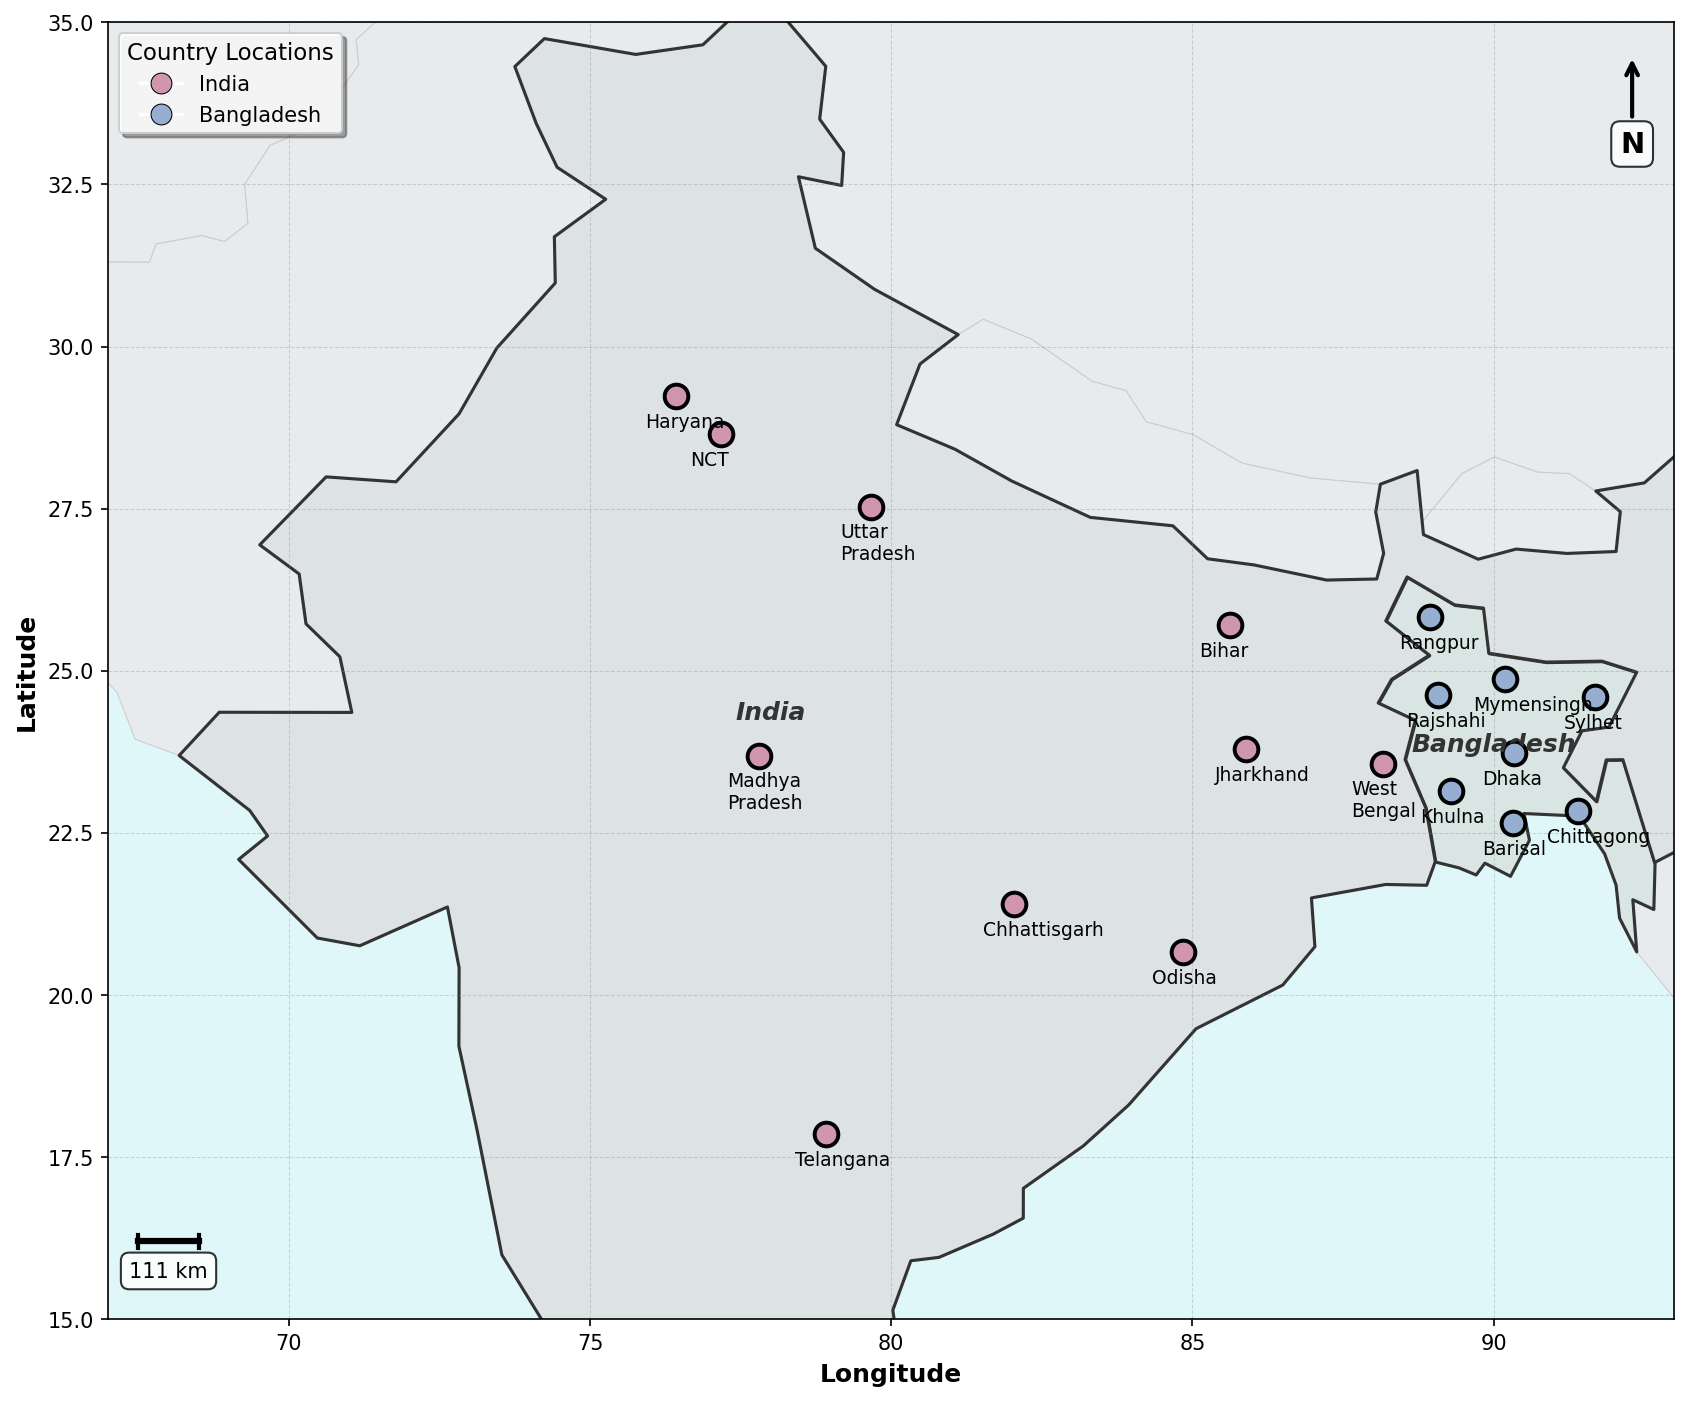


MAP CUSTOMIZATION OPTIONS:

1. Adjust text size: Change 'fontsize=8' in ax.annotate()
2. Change label position: Modify xytext=(5, 5) values
3. Adjust map bounds: Change minx, maxx, miny, maxy
4. Save high-res: Uncomment fig.savefig() lines
5. Remove label boxes: Remove 'bbox=dict(...)' from annotate


In [13]:
import warnings
warnings.filterwarnings('ignore', message='.*Shapely.*')
warnings.filterwarnings('ignore', category=DeprecationWarning)

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
import pandas as pd
import numpy as np

# Country color scheme
country_color_dict = {
    'India': '#D096AE',
    # 'Myanmar': '#990000',
    'Bangladesh': '#96AED0'
}

# Apply colors
metadata_region_all['color'] = metadata_region_all.apply(
    lambda x: country_color_dict[x.Country],
    axis=1
)

# metadata_bd['color'] = metadata_bd.apply(
#     lambda x: country_color_dict[x.Country],
#     axis=1
# )

# Create figure and axis
fig, ax = plt.subplots(1, 1, figsize=(12, 14), dpi=150)
# fig, ax = plt.subplots(1, 1, figsize=(12, 24), dpi=150)

# Load world map
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))

# Define the region bounds (focused on Bangladesh)
# minx, maxx = 87, 93  # Longitude bounds
# miny, maxy = 20, 27  # Latitude bounds

# Define the whole map (focused on Bangladesh and neighbors)
minx, maxx = 67, 93  # Longitude bounds
miny, maxy = 15, 35  # Latitude bounds

# Plot the base map
world.plot(ax=ax, color='#E8EBED', edgecolor='#CCCCCC', linewidth=0.5)

# Highlight Bangladesh
bangladesh = world[world.name == 'Bangladesh']
bangladesh.plot(ax=ax, color='#D8E5E3', edgecolor='#333333', linewidth=1.5)

# Highlight Bangladesh
india = world[world.name == 'India']
india.plot(ax=ax, color='#DDE3E5', edgecolor='#333333', linewidth=1.5)

# Plot ocean/water color as background
ax.set_facecolor('#E0F7FA')

# Plot markers for each country
for country, color in country_color_dict.items():
    country_data = metadata_region_all[metadata_region_all['Country'] == country]
    # country_data = metadata_bd[metadata_bd['Country'] == country]

    if len(country_data) > 0:
        # Plot black outline
        ax.scatter(country_data.Longitude, country_data.Latitude,
                  s=150, c='black', zorder=3, label=None)

        # Plot colored markers
        ax.scatter(country_data.Longitude, country_data.Latitude,
                  s=100, c=color, zorder=4, label=country, edgecolors='black', linewidths=0.5)

        # Add text labels
        for idx, row in country_data.iterrows():
            if idx.lower() == "azimpur_dhaka" or idx.lower() == "paltan_dhaka":
                continue

            ax.annotate(idx.replace(' ','\n'),
            # ax.annotate(idx.split("_")[0],
                       xy=(row['Longitude'], row['Latitude']),
                       xytext=(-15, -15) if not ' ' in idx else (-15,-25),  # Offset in points
                       textcoords='offset points',
                       fontsize=9,
                       # fontweight='bold',
                       color='black',
                       # bbox=dict(boxstyle='round,pad=0.3',
                       #          facecolor='white',
                       #          edgecolor='black',
                       #          alpha=0.8,
                       #          linewidth=0.5),
                       zorder=5)

# Set map bounds
ax.set_xlim(minx, maxx)
ax.set_ylim(miny, maxy)

# Add gridlines
ax.grid(True, linestyle='--', alpha=0.3, color='gray', linewidth=0.5)

# Labels and title
ax.set_xlabel('Longitude', fontsize=12, fontweight='bold')
ax.set_ylabel('Latitude', fontsize=12, fontweight='bold')
# ax.set_title('Geographic Distribution of Sampling Sites',
#              fontsize=14, fontweight='bold', pad=20)

# Add legend
legend_elements = [Line2D([0], [0], marker='o', color='w',
                         markerfacecolor=color, markersize=10,
                         markeredgecolor='black', markeredgewidth=0.5,
                         label=country)
                  for country, color in country_color_dict.items()]

ax.legend(handles=legend_elements,
         title='Country Locations',
         loc='upper left',
         fontsize=10,
         title_fontsize=11,
         frameon=True,
         fancybox=True,
         shadow=True,
         framealpha=0.9)

# Add scale bar (approximate)
scale_length_degrees = 1.0  # ~111 km at equator
scale_km = int(scale_length_degrees * 111)
scale_x = minx + 0.5
scale_y = miny + 1.2

ax.plot([scale_x, scale_x + scale_length_degrees], [scale_y, scale_y],
        'k-', linewidth=3, zorder=6)
ax.plot([scale_x, scale_x], [scale_y - 0.1, scale_y + 0.1],
        'k-', linewidth=2, zorder=6)
ax.plot([scale_x + scale_length_degrees, scale_x + scale_length_degrees],
        [scale_y - 0.1, scale_y + 0.1], 'k-', linewidth=2, zorder=6)
ax.text(scale_x + scale_length_degrees/2, scale_y - 0.55,
        f'{scale_km} km', ha='center', fontsize=10,
        bbox=dict(boxstyle='round,pad=0.4', facecolor='white',
                 edgecolor='black', alpha=0.8))

# Add country name labels
ax.text(90, 23.75, 'Bangladesh',
        fontsize=12, fontweight='bold',
        ha='center', style='italic',
        color='#333333',
        # bbox=dict(boxstyle='round,pad=0.5',
        #          facecolor='white',
        #          edgecolor='black',
        #          alpha=0.7)
        )

ax.text(78, 24.25, 'India',
        fontsize=12, fontweight='bold',
        ha='center', style='italic',
        color='#333333',
        # bbox=dict(boxstyle='round,pad=0.5',
        #          facecolor='white',
        #          edgecolor='black',
        #          alpha=0.7)
        )

# Add north arrow
arrow_x = maxx - 0.7
arrow_y = maxy - 1
ax.annotate('N', xy=(arrow_x, arrow_y + 0.5),
           xytext=(arrow_x, arrow_y - (maxy - miny)/20),
           fontsize=14, fontweight='bold', ha='center',
           arrowprops=dict(arrowstyle='->', lw=2, color='black'),
           bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                    edgecolor='black', alpha=0.8))

# Adjust layout manually instead of tight_layout to avoid warnings
plt.subplots_adjust(left=0.08, right=0.95, top=0.95, bottom=0.08)
plt.show()

# Optional: Save as high-resolution image
# fig.savefig('map_with_labels.png', dpi=300, bbox_inches='tight')
# fig.savefig('map_with_labels.pdf', bbox_inches='tight')  # For publications

print("\n" + "="*60)
print("MAP CUSTOMIZATION OPTIONS:")
print("="*60)
print("\n1. Adjust text size: Change 'fontsize=8' in ax.annotate()")
print("2. Change label position: Modify xytext=(5, 5) values")
print("3. Adjust map bounds: Change minx, maxx, miny, maxy")
print("4. Save high-res: Uncomment fig.savefig() lines")
print("5. Remove label boxes: Remove 'bbox=dict(...)' from annotate")
print("="*60)

# Measuring relative location of Wunderground Dhaka Station to locations of Dhaka

In [163]:
from geopy.distance import geodesic

w_s_location = 23.8441, 90.40230

# geodesic(origin, dest).kilometers

metadata_dhaka = metadata_all[metadata_all.Region=='Dhaka'].copy()
metadata_dhaka['distance_from_w_s'] = metadata_dhaka.apply(lambda x: geodesic((x.Latitude,x.Longitude), w_s_location).kilometers, axis=1)
metadata_dhaka_close_to_w_s = metadata_dhaka[metadata_dhaka.distance_from_w_s<50]
series_all[metadata_dhaka_close_to_w_s.index].to_csv('Dhaka_city_and_nearby_readings.csv')